# What does an ontology bring to PyMoDAQ data?

*A small, concrete example: UV-vis absorption spectra from two labs.*

**The idea in one sentence.** An ontology is a shared dictionary that a program can read:
each word has a fixed address on the web (an IRI), a definition, and links to other words.
If PyMoDAQ writes a few of these words next to the data it saves, an analysis script no longer
needs to know *who* recorded the file and *how they name things*: it can read what each
dataset **is**.

**The story.** Two labs measure the absorption spectrum of the same molecule.
Both save PyMoDAQ HDF5 files, but with their own habits:

| | Lab A | Lab B |
|---|---|---|
| What is saved | three raw spectra: dark, reference, sample | the transmittance, already computed |
| Names | `background`, `reference`, `signal` | `Trans` |
| Values | detector counts | percent |
| Spectral axis | wavelength in nm, increasing | photon energy in eV, decreasing |

We want one script that gives the absorbance spectrum and the position of its maximum for
any such file. We try it **without** and then **with** annotations.

The data is simulated (Lab A uses the simulated spectrometer of Bernhard Lang's PyMoDAQ
extension tutorial); the true answer is an absorption band peaking at **450 nm** with a maximum
absorbance of **0.3**.

In [1]:
import subprocess, sys
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np

from spectrum_demo import analysis, semantics, storage
from spectrum_demo import vocab as v

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
subprocess.run([sys.executable, str(ROOT / "scripts" / "make_datasets.py")], check=True)

LAB_COLORS = {"Lab A": "#2a78d6", "Lab B": "#eb6834"}
plt.rcParams.update({"figure.figsize": (9, 3.4), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})

written: lab_A.h5 lab_A_plain.h5 lab_B.h5 lab_B_plain.h5


## 1. The two files, as PyMoDAQ saves them today

We load the files **without annotations** first (`lab_A_plain.h5`, `lab_B_plain.h5`).
PyMoDAQ already stores a name, a unit string and an axis for each dataset.

Lab A: 'background'  values in 'counts'  axis 'Wavelength' in 'nm' [300.00 ... 900.00]
Lab A: 'reference'  values in 'counts'  axis 'Wavelength' in 'nm' [300.00 ... 900.00]
Lab A: 'signal'  values in 'counts'  axis 'Wavelength' in 'nm' [300.00 ... 900.00]
Lab B: 'Trans'  values in '%'  axis 'Photon energy' in 'eV' [4.00 ... 1.50]


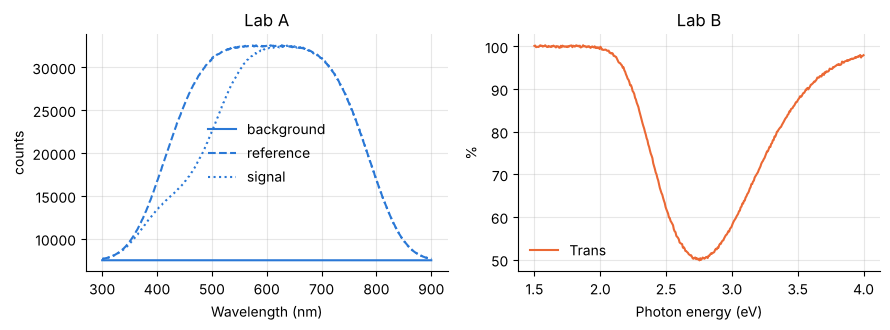

In [2]:
plain = {lab: storage.load(DATA / f"lab_{lab[-1]}_plain.h5")[0] for lab in ("Lab A", "Lab B")}

for lab, dte in plain.items():
    for dwa in dte:
        axis = dwa.axes[0]
        print(f"{lab}: '{dwa.name}'  values in '{dwa.units}'  "
              f"axis '{axis.label}' in '{axis.units}' "
              f"[{axis.get_data()[0]:.2f} ... {axis.get_data()[-1]:.2f}]")

fig, (ax_a, ax_b) = plt.subplots(1, 2)
for dwa, style in zip(plain["Lab A"], ("-", "--", ":")):
    ax_a.plot(dwa.axes[0].get_data(), dwa[0], style, color=LAB_COLORS["Lab A"], lw=1.5,
              label=dwa.name)
ax_a.set(title="Lab A", xlabel="Wavelength (nm)", ylabel="counts")
ax_a.legend(frameon=False)
dwa = plain["Lab B"][0]
ax_b.plot(dwa.axes[0].get_data(), dwa[0], color=LAB_COLORS["Lab B"], lw=1.5, label=dwa.name)
ax_b.set(title="Lab B", xlabel="Photon energy (eV)", ylabel="%")
ax_b.legend(frameon=False)
fig.tight_layout()

A human sees quickly that these are the same kind of measurement. A program does not:
`background`, `reference`, `signal`, `Trans` are just strings, and nothing says that
`background` is a dark spectrum to subtract or that `Trans` is a transmittance.

## 2. Before: each lab's own script

Each lab wrote a script for its own files. Each one works at home.

In [3]:
print("Lab A script on Lab A file:", analysis.lab_a_script(plain["Lab A"]))
print("Lab B script on Lab B file:", analysis.lab_b_script(plain["Lab B"]))

Lab A script on Lab A file: Result(peak at 450.3 nm, A max = 0.302, from ['background', 'reference', 'signal'])
Lab B script on Lab B file: Result(peak at 450.3 nm, A max = 0.302, from ['Trans'])


Now swap the files.

In [4]:
try:
    analysis.lab_a_script(plain["Lab B"])
except Exception as error:
    print("Lab A script on Lab B file -> crash:", type(error).__name__, error)

wrong = analysis.lab_b_script(plain["Lab A"])
print("Lab B script on Lab A file -> no error, but:", wrong)

Lab A script on Lab B file -> crash: AttributeError 'NoneType' object has no attribute 'axes'
Lab B script on Lab A file -> no error, but: Result(peak at 2.4 nm, A max = -1.874, from ['background'])


The first case is the *good* failure: it crashes. The second one is worse: the script
runs, takes the dark spectrum for a transmittance and the wavelengths for energies, and returns
a "peak at 2.4 nm" with a negative absorbance. Nothing warns the user.

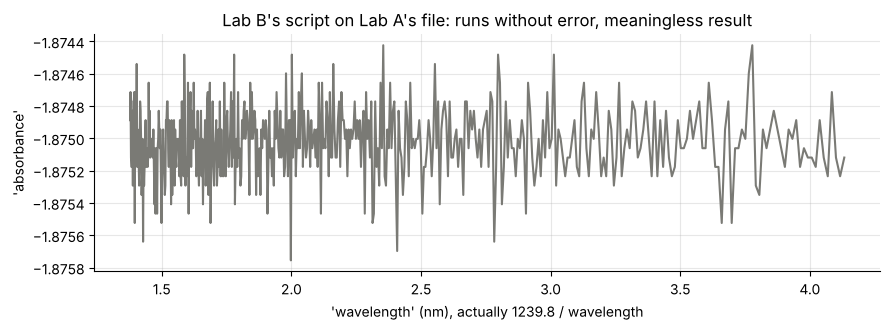

In [5]:
fig, ax = plt.subplots()
ax.plot(wrong.wavelength_nm, wrong.absorbance, color="#7a7a75", lw=1.5)
ax.set(title="Lab B's script on Lab A's file: runs without error, meaningless result",
       xlabel="'wavelength' (nm), actually 1239.8 / wavelength", ylabel="'absorbance'")
fig.tight_layout()

## 3. The usual fix: a configuration per lab

We write one script and a configuration table that says, for each lab, which name means
what and which units are used.

In [6]:
for lab, config in analysis.MANUAL_CONFIG.items():
    print(lab, config)

for lab, dte in plain.items():
    print(lab, "->", analysis.analyse_with_config(dte, analysis.MANUAL_CONFIG[lab.replace(" ", "")]))

LabA {'dark': 'background', 'reference': 'reference', 'sample': 'signal', 'axis': 'nm'}
LabB {'transmittance': 'Trans', 'transmittance_scale': 0.01, 'axis': 'eV'}
Lab A -> Result(peak at 450.3 nm, A max = 0.302, from ['background', 'reference', 'signal'])
Lab B -> Result(peak at 450.3 nm, A max = 0.302, from ['Trans'])


It works, but:

* someone had to **ask each lab** (or read their notebook) to write that table;
* the table lives **outside the data files**: send a file to a colleague and the knowledge
  stays behind;
* a third lab means a third entry, and a typo in the table gives a silent error again.

## 4. After: the data says what it is

The annotated files (`lab_A.h5`, `lab_B.h5`) hold the same arrays. The only difference:
when the data object was created, five extra attributes were added to it with PyMoDAQ's own
`add_extra_attribute` (see `src/spectrum_demo/simulation.py`):

```python
dwa.add_extra_attribute(
    semantic_iri="https://w3id.org/pymodaq/spectro#DarkSpectrum",      # what it is
    quantity_kind="http://qudt.org/vocab/quantitykind/Count",           # what is measured
    unit_iri="http://qudt.org/vocab/unit/NUM",                         # in which unit
    axis_quantity_kind="http://qudt.org/vocab/quantitykind/Wavelength", # along what
    axis_unit_iri="http://qudt.org/vocab/unit/NanoM",                  # in which unit
)
```

PyMoDAQ's savers write every extra attribute next to the data in the HDF5 file, and its loader
gives them back. Here is what is physically in Lab B's file, read with plain `h5py`
(no PyMoDAQ, no demo code). PyMoDAQ stores each attribute as a small JSON record (type and
value); we print the raw record once, then only the values:

In [7]:
import json

with h5py.File(DATA / "lab_B.h5", "r") as f:
    node = f["/RawData/Spectrometer/Data1D/CH00/Data00"]
    print("raw HDF5 attribute:", node.attrs["unit_iri"], "\n")
    for key in ("units", *v.ANNOTATION_KEYS):
        value = json.loads(node.attrs[key])["data"].strip("'")
        print(f"{key:20s} {value}")

raw HDF5 attribute: {"module": "builtins", "type": "str", "data": "'http://qudt.org/vocab/unit/PERCENT'"} 

units                %
semantic_iri         https://w3id.org/pymodaq/spectro#TransmittanceSpectrum
quantity_kind        http://qudt.org/vocab/quantitykind/Transmittance
unit_iri             http://qudt.org/vocab/unit/PERCENT
axis_quantity_kind   http://qudt.org/vocab/quantitykind/Energy
axis_unit_iri        http://qudt.org/vocab/unit/EV


Each IRI is an entry of the dictionary. The program can look it up, the same way a person
would read a definition. This is what the ontology says about the annotations it finds in the
two files:

In [8]:
annotated = {lab: storage.load(DATA / f"lab_{lab[-1]}.h5") for lab in ("Lab A", "Lab B")}

for lab, (dte, file_attrs) in annotated.items():
    print(f"=== {lab}  (technique: {semantics.label(file_attrs[v.TECHNIQUE_IRI])})")
    for dwa in dte:
        concept = getattr(dwa, v.SEMANTIC_IRI)
        print(f"'{dwa.name}' is a {semantics.label(concept)}: {semantics.definition(concept)}")
        print(f"    values: {semantics.label(getattr(dwa, v.QUANTITY_KIND))} "
              f"in {semantics.label(getattr(dwa, v.UNIT_IRI))};  "
              f"axis: {semantics.label(getattr(dwa, v.AXIS_QUANTITY_KIND))} "
              f"in {semantics.label(getattr(dwa, v.AXIS_UNIT_IRI))}")

=== Lab A  (technique: ultraviolet-visible spectrophotometry)
'background' is a dark spectrum: Intensity spectrum recorded with the light blocked; it measures the detector offset and dark current, to be subtracted from the sample and reference spectra.
    values: Count in Number;  axis: Wavelength in Nanometre
'reference' is a reference spectrum: Intensity spectrum recorded in the same conditions as the sample spectrum but without the absorbing species (empty beam, solvent or bare substrate).
    values: Count in Number;  axis: Wavelength in Nanometre
'signal' is a sample spectrum: Intensity spectrum recorded with the light passing through the sample.
    values: Count in Number;  axis: Wavelength in Nanometre
=== Lab B  (technique: ultraviolet-visible spectrophotometry)
'Trans' is a transmittance spectrum: Spectrum of the fraction of the incident light transmitted by the sample, T = (I - I_dark) / (I0 - I_dark).
    values: Transmittance in Percent;  axis: Energy in Electron Volt


## 5. One analysis, no configuration

`analysis.analyse` contains no lab name, no channel name and no unit string. It asks:

* *Is there a spectrum that is a transmittance?* If yes, convert its unit to a fraction with
  the conversion factor given by QUDT (the units ontology): percent → × 0.01.
* *Otherwise, which spectra are the dark, the reference and the sample?* Then
  T = (sample − dark) / (reference − dark).
* *Is the axis a wavelength or an energy?* Convert to nm (λ = hc/E for an energy).

It also writes down its reasoning:

In [9]:
results = {}
for lab, (dte, _) in annotated.items():
    results[lab] = analysis.analyse(dte)
    print(f"=== {lab}: {results[lab]}")
    for step in results[lab].log:
        print("   ", step)

=== Lab A: Result(peak at 450.3 nm, A max = 0.302, from ['background', 'reference', 'signal'])
    'background' is the dark spectrum
    'reference' is the reference spectrum
    'signal' is the sample spectrum
    transmittance = (sample - dark) / (reference - dark)
    axis is a Wavelength in Nanometre: converted to nm
    absorbance = -log10(transmittance); axis sorted by increasing wavelength
=== Lab B: Result(peak at 450.3 nm, A max = 0.302, from ['Trans'])
    'Trans' is a transmittance spectrum in Percent: multiplied by 0.01 (QUDT) to get a fraction
    axis is an Energy in Electron Volt: converted to wavelength with lambda = h c / E
    absorbance = -log10(transmittance); axis sorted by increasing wavelength


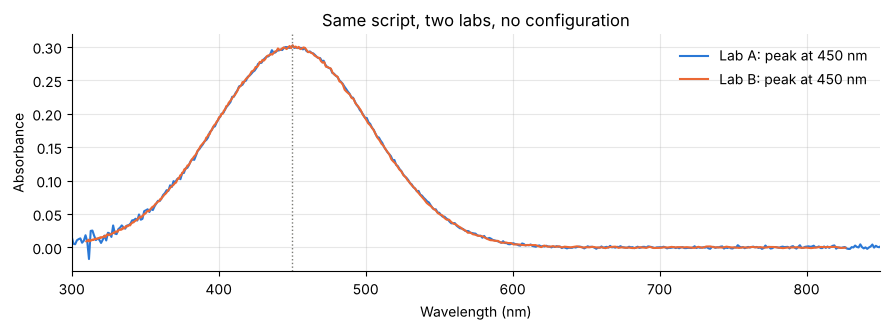

In [10]:
fig, ax = plt.subplots()
for lab, result in results.items():
    ax.plot(result.wavelength_nm, result.absorbance, color=LAB_COLORS[lab], lw=1.5,
            label=f"{lab}: peak at {result.peak_wavelength_nm:.0f} nm")
ax.axvline(450, color="#7a7a75", lw=1, ls=":")
ax.set(title="Same script, two labs, no configuration", xlabel="Wavelength (nm)",
       ylabel="Absorbance", xlim=(300, 850))
ax.legend(frameon=False)
fig.tight_layout()

Both labs now give the same spectrum, with the expected maximum near 450 nm, from files that
share no naming convention.

## 6. When something is missing, it says so

Give the same function a file without annotations: instead of guessing (section 2), it
refuses and says what is missing.

In [11]:
try:
    analysis.analyse(plain["Lab B"])
except analysis.AnnotationError as error:
    print(error)

Cannot analyse without guessing:
  - 'Trans' has no semantic_iri, quantity_kind, unit_iri, axis_quantity_kind, axis_unit_iri


## 7. What is in the ontology, concretely?

Two small files in `ontology/`:

* `spectro.ttl`: the new vocabulary of this demo, about ten terms (measurement, spectrum,
  sample / reference / dark spectrum, transmittance and absorbance spectrum, spectral axis).
  Each term has a label, a definition and, where it exists, a link to an established ontology
  (CHMO for the technique, QUDT for quantities and units).
* `external_excerpt.ttl`: the few QUDT and CHMO terms used, copied so that the demo runs
  offline.

The words are organised in a hierarchy, and the program can use it. For instance the three raw
spectra are all *intensity spectra*, while the transmittance is not:

In [12]:
for concept in ("SampleSpectrum", "ReferenceSpectrum", "DarkSpectrum", "TransmittanceSpectrum"):
    print(f"{concept:22s} is an intensity spectrum: "
          f"{semantics.is_a(v.SPECTRO[concept], v.SPECTRO.IntensitySpectrum)}")

print()
for unit in ("PERCENT", "FRACTION", "NanoM", "EV"):
    print(f"QUDT: 1 {semantics.label(v.UNIT[unit]):14s} = {semantics.to_si_factor(v.UNIT[unit]):g} SI unit")

SampleSpectrum         is an intensity spectrum: True
ReferenceSpectrum      is an intensity spectrum: True
DarkSpectrum           is an intensity spectrum: True
TransmittanceSpectrum  is an intensity spectrum: False

QUDT: 1 Percent        = 0.01 SI unit
QUDT: 1 Fraction       = 1 SI unit
QUDT: 1 Nanometre      = 1e-09 SI unit
QUDT: 1 Electron Volt  = 1.60218e-19 SI unit


## 8. Second layer: a description that other tools can search (JSON-LD)

The HDF5 file stays the data container. From its annotations we generate a small JSON-LD
file, a standard web format for linked data, that describes what the file contains and what
was derived from it. It holds no arrays, only the description.

In [13]:
OUT = ROOT / "data"
jsonld_files = []
for lab, (dte, file_attrs) in annotated.items():
    name = f"lab_{lab[-1]}"
    jsonld_files.append(semantics.export_jsonld(
        dte, OUT / f"{name}.jsonld", file_iri=f"https://example.org/data/{name}.h5",
        file_attrs=file_attrs, result=results[lab]))

print((OUT / "lab_B.jsonld").read_text())

{
  "@context": {
    "obo": "http://purl.obolibrary.org/obo/",
    "prov": "http://www.w3.org/ns/prov#",
    "quantitykind": "http://qudt.org/vocab/quantitykind/",
    "qudt": "http://qudt.org/schema/qudt/",
    "rdfs": "http://www.w3.org/2000/01/rdf-schema#",
    "sosa": "http://www.w3.org/ns/sosa/",
    "spectro": "https://w3id.org/pymodaq/spectro#",
    "unit": "http://qudt.org/vocab/unit/"
  },
  "@graph": [
    {
      "@id": "https://example.org/data/lab_B.h5#/RawData/Spectrometer/Data1D/CH00/Data00",
      "@type": "spectro:TransmittanceSpectrum",
      "qudt:hasQuantityKind": {
        "@id": "quantitykind:Transmittance"
      },
      "qudt:hasUnit": {
        "@id": "unit:PERCENT"
      },
      "rdfs:label": "Trans",
      "spectro:hasSpectralAxis": {
        "@id": "_:N8ad05d7fc6134bce83dc77c842c285a3"
      },
      "spectro:hdf5Path": "/RawData/Spectrometer/Data1D/CH00/Data00"
    },
    {
      "@id": "_:N8ad05d7fc6134bce83dc77c842c285a3",
      "@type": "spectro:Spectr

## 9. Bonus: one question asked to both labs at once

Load the two JSON-LD descriptions and the ontology in one graph, and ask a question in SPARQL
(the query language of linked data). Note that the question uses the word
*intensity spectrum*, which no file uses: the hierarchy of the ontology answers it.

In [14]:
from rdflib import Graph

graph = Graph()
for path in jsonld_files:
    graph.parse(path, format="json-ld")
graph += semantics.ontology()

QUERY_RAW = '''
PREFIX spectro: <https://w3id.org/pymodaq/spectro#>
PREFIX sosa: <http://www.w3.org/ns/sosa/>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>
SELECT ?measurement ?name ?role WHERE {
  ?m rdfs:label ?measurement ; sosa:hasResult ?spectrum .
  ?spectrum rdfs:label ?name ; a ?class .
  ?class rdfs:subClassOf* spectro:IntensitySpectrum ; rdfs:label ?role .
  FILTER(lang(?role) = "en")
} ORDER BY ?measurement ?name
'''
print("Which raw intensity spectra are available, and what is each one?")
for row in graph.query(QUERY_RAW):
    print("  ", " | ".join(map(str, row)))

QUERY_PEAK = '''
PREFIX spectro: <https://w3id.org/pymodaq/spectro#>
PREFIX sosa: <http://www.w3.org/ns/sosa/>
PREFIX prov: <http://www.w3.org/ns/prov#>
PREFIX qudt: <http://qudt.org/schema/qudt/>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>
SELECT DISTINCT ?measurement ?peak_nm ?axis_unit WHERE {
  ?m rdfs:label ?measurement ; sosa:hasResult ?spectrum .
  ?absorbance prov:wasDerivedFrom ?spectrum ;
              spectro:peakWavelength/qudt:numericValue ?peak_nm .
  ?spectrum spectro:hasSpectralAxis/qudt:hasUnit/rdfs:label ?axis_unit .
  FILTER(lang(?axis_unit) = "en")
} ORDER BY ?measurement
'''
print("\nWhere is the absorbance maximum, and in which unit was the axis recorded?")
for row in graph.query(QUERY_PEAK):
    print("  ", " | ".join(map(str, row)))

Which raw intensity spectra are available, and what is each one?


   absorption measurement, Lab A | background | dark spectrum
   absorption measurement, Lab A | reference | reference spectrum
   absorption measurement, Lab A | signal | sample spectrum

Where is the absorbance maximum, and in which unit was the axis recorded?


   absorption measurement, Lab A | 450.3 | Nanometre
   absorption measurement, Lab B | 450.3 | Electron Volt


## 10. What this shows, and what it does not (yet)

**Shown here**

* The annotations are five strings per dataset, written with PyMoDAQ's existing
  `extra_attributes`; PyMoDAQ already saves and reloads them, so no change to PyMoDAQ was
  needed for this demo.
* One analysis script handles two incompatible conventions with no configuration, and refuses
  to guess when information is missing.
* The same annotations give, for free, a searchable description (JSON-LD) and cross-lab
  queries.

**Not shown, or simplified**

* *Who writes the annotations?* Here the simulation does. In real use the natural place is
  the code that already knows the role of each spectrum: for instance the Absorption extension
  of the tutorial, which has *Take Background* and *Take Reference* buttons, knows exactly which
  spectrum is the dark and which is the reference.
* PyMoDAQ `Axis` objects have no extra attributes, so the axis annotations are stored on the
  data object (`axis_quantity_kind`, `axis_unit_iri`).
* The vocabulary is a draft (namespace not reserved, not reviewed by spectroscopists).
* QUDT has no term named "decadic absorbance"; we use `TransmittanceDensity`, defined as
  −log10 of the transmittance.

**Possible next steps**

1. A small PyMoDAQ CustomApp with a *with / without ontology* switch, for people who do not
   use notebooks.
2. Write the annotations in the Absorption extension at acquisition time.
3. Transient absorption (pump-probe) as a second technique, reusing the same vocabulary.
4. Query many files from different labs (the SPARQL of section 9, at a larger scale).